# 哺乳類影像分類（原型正則化 + 校正，一鍵 Colab 版）
# Mammal Image Classification (prototype regularisation + calibration, one-click Colab)

Final executed notebook of the YZU EE undergraduate graduation project *基於深度學習之哺乳動物影像分類系統設計與評估*.

Pipeline: KaggleHub download -> cleaning (min side / Laplacian blur / pHash dedup) -> stratified split -> `tf.data` -> MobileNetV2 + 128-d embedding + class prototypes (center loss) -> custom training loop -> logit adjustment + temperature scaling -> test report / confusion matrix / UMAP / reliability diagram + ECE -> Keras + TFLite export -> single-image demo.

> Published copy: outputs are kept as executed on Google Colab (TensorFlow 2.19.0). Notebook metadata was cleaned, progress bars were stripped, a long TFLite tensor-capture log was trimmed, and image outputs that show third-party photos (prototype image grid, demo upload) were removed.


In [2]:

# 參數
FIXED_CLASSES = ['bear','cat','dog','elephant','goat','horse','lion','tiger','wolf']
MIN_SIDE = 160; BLUR_THR = 60.0; PHASH_DUP_THR = 6
IMG_SIZE = 224; BATCH_SIZE = 32; EMBED_DIM = 128
LAMBDA_CENTER = 0.5; PROTO_MOMENTUM = 0.1; EPOCHS = 10; SEED = 1337
RAW_DIR='/content/dataset_raw'; CLEAN_DIR='/content/dataset_clean'; SPLIT_DIR='/content/subset_clean'; EXPORT_DIR='/content/export'
import os, random, numpy as np, tensorflow as tf
os.makedirs(EXPORT_DIR, exist_ok=True); np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
print('Config OK')


Config OK


In [3]:

# 安裝與匯入
!pip -q install kagglehub umap-learn opencv-python imagehash scikit-learn tqdm
import os, io, glob, shutil, zipfile, math
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
import cv2, imagehash, kagglehub, umap
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing import image_dataset_from_directory
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from google.colab import files as colab_files
print('TF:', tf.__version__)


TF: 2.19.0


In [4]:

# KaggleHub 下載
def ensure(d): os.makedirs(d, exist_ok=True)
print('Downloading anirudhg15/mammals-classification via KaggleHub')
try:
    path = kagglehub.dataset_download('anirudhg15/mammals-classification')
except Exception:
    kagglehub.login(); path = kagglehub.dataset_download('anirudhg15/mammals-classification')
print('Local path:', path)
ensure(RAW_DIR); exts=('.jpg','.jpeg','.png','.bmp','.webp'); moved=0
for p in glob.glob(os.path.join(path,'**','*.*'), recursive=True):
    if p.lower().endswith(exts):
        cls = Path(p).parent.name
        if cls not in FIXED_CLASSES: continue
        dst=os.path.join(RAW_DIR, cls); ensure(dst); shutil.copy2(p, os.path.join(dst, Path(p).name)); moved+=1
print('Copied images:', moved)
class_counts={c:len(glob.glob(os.path.join(RAW_DIR,c,'*'))) for c in FIXED_CLASSES}; print('Counts:', class_counts)


Extracting files...


Local path: /root/.cache/kagglehub/datasets/anirudhg15/mammals-classification/versions/1
Copied images: 827
Counts: {'bear': 95, 'cat': 99, 'dog': 97, 'elephant': 97, 'goat': 85, 'horse': 67, 'lion': 94, 'tiger': 96, 'wolf': 97}


In [5]:

# 清理
def lap_var(pil_img): import cv2, numpy as np; return cv2.Laplacian(np.array(pil_img.convert('L')), cv2.CV_64F).var()
kept=0; total=0
for cls in FIXED_CLASSES:
    srcs=sorted(glob.glob(os.path.join(RAW_DIR, cls, '*')));
    if not srcs: continue
    import imagehash
    hashes=[]; from PIL import Image
    for p in srcs:
        try: h=imagehash.phash(Image.open(p).convert('RGB')); hashes.append((p,h))
        except: pass
    dup=set()
    if PHASH_DUP_THR is not None:
        for i in range(len(hashes)):
            for j in range(i+1,len(hashes)):
                if (hashes[i][1]-hashes[j][1])<=PHASH_DUP_THR: dup.add(hashes[j][0])
    dst=os.path.join(CLEAN_DIR, cls); os.makedirs(dst, exist_ok=True)
    for p in srcs:
        total+=1
        if p in dup: continue
        try:
            im=Image.open(p).convert('RGB'); w,h=im.size
            if min(w,h)<MIN_SIDE: continue
            if lap_var(im)<BLUR_THR: continue
            im.save(os.path.join(dst, Path(p).name), quality=95); kept+=1
        except: pass
print(f'Clean kept {kept}/{total}')


Clean kept 761/827


In [6]:

# 分層切分
from sklearn.model_selection import train_test_split
rows=[]
for cls in FIXED_CLASSES:
    for p in glob.glob(os.path.join(CLEAN_DIR, cls, '*')): rows.append((cls,p))
import pandas as pd
df=pd.DataFrame(rows, columns=['class','path'])
if len(df)==0: raise RuntimeError('No images after cleaning')
train_val, test = train_test_split(df, test_size=0.1, stratify=df['class'], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.2222, stratify=train_val['class'], random_state=SEED)
def dump(split, sub):
    for cls, path in sub.values:
        dst=os.path.join(SPLIT_DIR, split, cls, Path(path).name)
        os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy2(path, dst)
dump('train',train); dump('val',val); dump('test',test)
print('Split:', len(train), len(val), len(test))


Split: 532 152 77


In [7]:

# Dataset pipeline
def make_ds(root=SPLIT_DIR):
    from tensorflow.keras.preprocessing import image_dataset_from_directory
    def ld(split, shuffle):
        return image_dataset_from_directory(os.path.join(root,split),
            labels='inferred', label_mode='int', image_size=(IMG_SIZE,IMG_SIZE),
            batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED)
    train=ld('train',True); val=ld('val',False); test=ld('test',False)
    names=train.class_names
    AUTOTUNE=tf.data.AUTOTUNE
    return train.cache().prefetch(AUTOTUNE), val.cache().prefetch(AUTOTUNE), test.cache().prefetch(AUTOTUNE), names
train_ds, val_ds, test_ds, class_names = make_ds(); K=len(class_names); print('Classes:', class_names)


Found 532 files belonging to 9 classes.
Found 152 files belonging to 9 classes.
Found 77 files belonging to 9 classes.
Classes: ['bear', 'cat', 'dog', 'elephant', 'goat', 'horse', 'lion', 'tiger', 'wolf']


In [8]:

# 模型
from tensorflow.keras import layers, Model
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE,IMG_SIZE,3), include_top=False, weights='imagenet')
base.trainable=False
inputs=layers.Input(shape=(IMG_SIZE,IMG_SIZE,3))
x=layers.Rescaling(1./127.5, offset=-1)(inputs)
x=base(x, training=False)
x=layers.GlobalAveragePooling2D()(x)
embedding=layers.Dense(128, activation=None, name='embedding')(x)
embedding=layers.BatchNormalization()(embedding)
logits=layers.Dense(K, activation=None, name='logits')(embedding)
model=Model(inputs,[logits,embedding])
prototypes=tf.Variable(tf.zeros((K,128), dtype=tf.float32), trainable=False)
ce_loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer=tf.keras.optimizers.Adam(1e-3)


In [9]:

# 訓練（自訂迴圈）
history={'train_loss':[],'train_acc':[],'val_loss':[],'val_acc':[]}
def eval_epoch(ds):
    tloss, corr, n = 0.0, 0, 0
    for images, labels in ds:
        labels=tf.cast(labels, tf.int32)
        logits,_=model(images, training=False)
        loss=ce_loss_fn(labels, logits)
        tloss += float(loss)*images.shape[0]
        preds=tf.argmax(logits, axis=1, output_type=tf.int32)
        corr += int(tf.reduce_sum(tf.cast(preds==labels, tf.int32)))
        n += images.shape[0]
    return tloss/n, corr/n
for e in range(1, EPOCHS+1):
    print(f'\nEpoch {e}/{EPOCHS}')
    tloss, corr, n = 0.0, 0, 0
    for images, labels in train_ds:
        labels=tf.cast(labels, tf.int32)
        with tf.GradientTape() as tape:
            logits, embeds = model(images, training=True)
            ce=ce_loss_fn(labels, logits)
            centers=tf.gather(prototypes, labels)
            c_loss=tf.reduce_mean(tf.reduce_sum(tf.square(embeds-centers), axis=1))
            loss=ce + 0.5*c_loss
        grads=tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        en=embeds.numpy(); ln=labels.numpy()
        import numpy as np
        for cls_idx in np.unique(ln):
            mask=(ln==cls_idx); mean=en[mask].mean(axis=0)
            prototypes[cls_idx].assign((1-0.1)*prototypes[cls_idx] + 0.1*mean)
        tloss += float(loss)*images.shape[0]
        preds=tf.argmax(logits, axis=1, output_type=tf.int32)
        corr += int(tf.reduce_sum(tf.cast(preds==labels, tf.int32)))
        n += images.shape[0]
    tr_loss=tloss/n; tr_acc=corr/n
    va_loss, va_acc=eval_epoch(val_ds)
    history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
    history['val_loss'].append(va_loss); history['val_acc'].append(va_acc)
    print(f' - train_loss: {tr_loss:.4f} - train_acc: {tr_acc:.4f} - val_loss: {va_loss:.4f} - val_acc: {va_acc:.4f}')



Epoch 1/10
 - train_loss: 45.4871 - train_acc: 0.7462 - val_loss: 0.6500 - val_acc: 0.8224

Epoch 2/10
 - train_loss: 17.7016 - train_acc: 0.9417 - val_loss: 0.5382 - val_acc: 0.8224

Epoch 3/10
 - train_loss: 11.5344 - train_acc: 0.9699 - val_loss: 0.4781 - val_acc: 0.8553

Epoch 4/10
 - train_loss: 9.4384 - train_acc: 0.9831 - val_loss: 0.4378 - val_acc: 0.8882

Epoch 5/10
 - train_loss: 8.2038 - train_acc: 0.9887 - val_loss: 0.4175 - val_acc: 0.8947

Epoch 6/10
 - train_loss: 7.3297 - train_acc: 0.9906 - val_loss: 0.4073 - val_acc: 0.8947

Epoch 7/10
 - train_loss: 6.6611 - train_acc: 0.9944 - val_loss: 0.4018 - val_acc: 0.8947

Epoch 8/10
 - train_loss: 6.1262 - train_acc: 0.9944 - val_loss: 0.3993 - val_acc: 0.8882

Epoch 9/10
 - train_loss: 5.6853 - train_acc: 0.9944 - val_loss: 0.3987 - val_acc: 0.8947

Epoch 10/10
 - train_loss: 5.3143 - train_acc: 0.9944 - val_loss: 0.3995 - val_acc: 0.8882


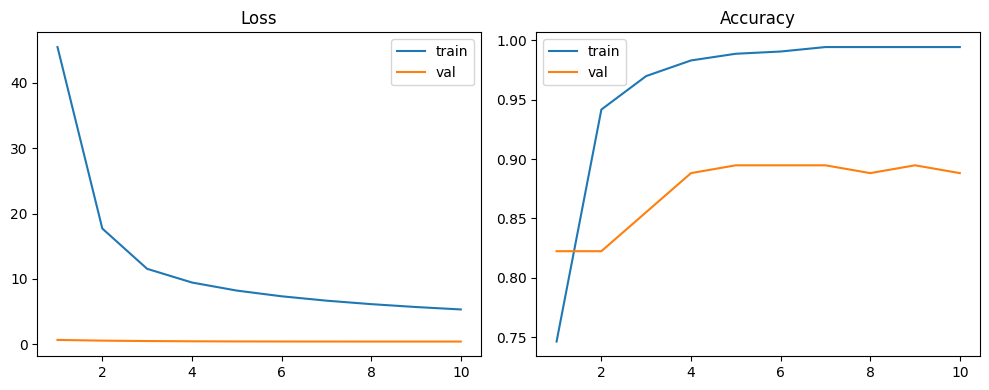

In [10]:

# 訓練曲線
ep=range(1,len(history['train_loss'])+1)
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(ep, history['train_loss'], label='train'); plt.plot(ep, history['val_loss'], label='val'); plt.title('Loss'); plt.legend()
plt.subplot(1,2,2); plt.plot(ep, history['train_acc'], label='train'); plt.plot(ep, history['val_acc'], label='val'); plt.title('Accuracy'); plt.legend()
plt.tight_layout(); plt.show()


In [11]:

# Logit Adjustment + 溫度標定
train_files=[]; counts={cls:0 for cls in class_names}
for cls in class_names:
    paths=glob.glob(os.path.join(SPLIT_DIR,'train',cls,'*'))
    for p in paths: train_files.append((p,cls)); counts[cls]+=1
total=len(train_files); priors={cls: counts[cls]/total for cls in class_names}
import numpy as np
logit_adjustment=np.array([-np.log(max(priors[cls],1e-8)) for cls in class_names], dtype=np.float32)
val_logits_list=[]; val_labels_list=[]
for images, labels in val_ds:
    logits,_=model(images, training=False)
    val_logits_list.append(logits.numpy()+logit_adjustment); val_labels_list.append(labels.numpy())
val_logits=np.vstack(val_logits_list); val_labels=np.concatenate(val_labels_list)
def nll(T):
    if T<=1e-6: return np.inf
    s=val_logits/T; m=s.max(axis=1, keepdims=True); exp=np.exp(s-m); p=exp/exp.sum(axis=1, keepdims=True)
    return (-np.log(p[np.arange(len(val_labels)), val_labels]+1e-12)).mean()
grid=np.linspace(0.1,5.0,50); vals=[nll(t) for t in grid]
best=grid[int(np.argmin(vals))]
fine=np.linspace(max(0.1,best-0.5), best+0.5, 50); fvals=[nll(t) for t in fine]
best_T=fine[int(np.argmin(fvals))]; print('Best T =', best_T)


Best T = 0.889795918367347


Test Acc: 89.61%

Classification Report:
              precision    recall  f1-score   support

        bear     0.8000    0.8889    0.8421         9
         cat     0.9000    1.0000    0.9474         9
         dog     1.0000    0.7500    0.8571         8
    elephant     1.0000    1.0000    1.0000        10
        goat     0.8750    0.8750    0.8750         8
       horse     0.7143    0.8333    0.7692         6
        lion     1.0000    0.7778    0.8750         9
       tiger     1.0000    1.0000    1.0000         9
        wolf     0.8000    0.8889    0.8421         9

    accuracy                         0.8961        77
   macro avg     0.8988    0.8904    0.8898        77
weighted avg     0.9063    0.8961    0.8965        77



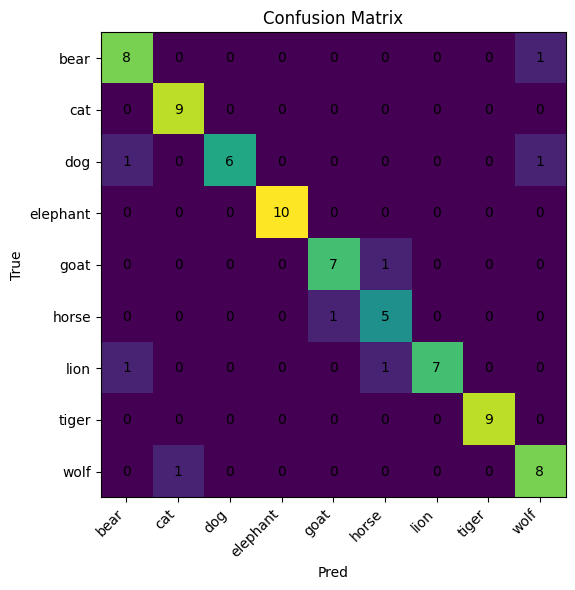

In [12]:

# 測試評估
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
y_true=[]; y_pred=[]
for images, labels in test_ds:
    logits,_=model(images, training=False)
    preds=tf.argmax(logits, axis=1, output_type=tf.int32)
    y_pred.extend(list(preds.numpy())); y_true.extend(list(labels.numpy()))
acc=accuracy_score(y_true,y_pred); print(f'Test Acc: {acc*100:.2f}%\n')
print('Classification Report:'); print(classification_report(y_true,y_pred, target_names=class_names, digits=4))
cm=confusion_matrix(y_true,y_pred)
import matplotlib.pyplot as plt, numpy as np
plt.figure(figsize=(6,6)); plt.imshow(cm); plt.title('Confusion Matrix'); plt.xlabel('Pred'); plt.ylabel('True')
ticks=np.arange(len(class_names)); plt.xticks(ticks, class_names, rotation=45, ha='right'); plt.yticks(ticks, class_names)
for i in range(len(class_names)):
    for j in range(len(class_names)): plt.text(j,i,str(cm[i,j]), ha='center', va='center')
plt.tight_layout(); plt.show()


Found 532 files belonging to 9 classes.


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


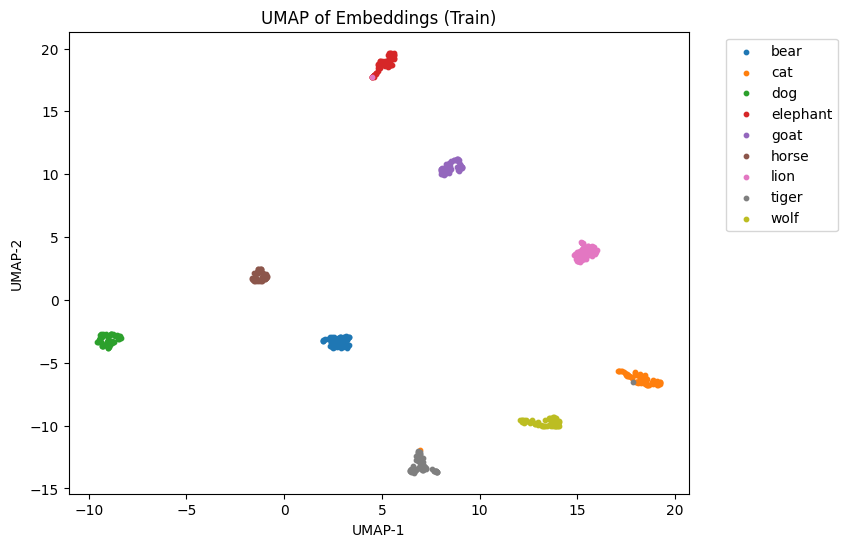

In [13]:

# UMAP（訓練集嵌入）
train_embeds=[]; train_lbls=[]
for images, labels in image_dataset_from_directory(os.path.join(SPLIT_DIR,'train'),
        labels='inferred', label_mode='int', image_size=(IMG_SIZE,IMG_SIZE),
        batch_size=64, shuffle=False).unbatch().batch(64):
    _,emb=model(images, training=False); train_embeds.append(emb.numpy()); train_lbls.append(labels.numpy())
train_embeds=np.vstack(train_embeds); train_lbls=np.concatenate(train_lbls)
import umap, matplotlib.pyplot as plt, numpy as np
reducer=umap.UMAP(n_components=2, random_state=42); emb2d=reducer.fit_transform(train_embeds)
plt.figure(figsize=(8,6))
for i,cls in enumerate(class_names):
    idx=(train_lbls==i); plt.scatter(emb2d[idx,0], emb2d[idx,1], s=10, label=cls)
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left'); plt.title('UMAP of Embeddings (Train)'); plt.xlabel('UMAP-1'); plt.ylabel('UMAP-2'); plt.show()


### Nearest-to-prototype training images

The next cell shows, for each class, the training image whose embedding is closest to the class prototype. Its image output (a 3x3 grid of dataset photos) is not included in the published notebook; re-run the notebook to regenerate it.


In [14]:

ds_all = image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'train'),
    labels='inferred',
    label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=64,
    shuffle=False
)

file_paths = np.array(ds_all.file_paths)
class_names = ds_all.class_names


embs2 = []
lbls2 = []
for images, labels in ds_all:
    _, emb = model(images, training=False)
    embs2.append(emb.numpy())
    lbls2.append(labels.numpy())

embs2 = np.vstack(embs2)
lbls2 = np.concatenate(lbls2)


prototype_image_paths = {}
for i, cls in enumerate(class_names):
    idxs = np.where(lbls2 == i)[0]
    if idxs.size == 0:
        continue
    proto = prototypes[i].numpy()
    d = np.sum((embs2[idxs] - proto) ** 2, axis=1)
    nearest = idxs[np.argmin(d)]
    prototype_image_paths[cls] = file_paths[nearest]


import math, matplotlib.pyplot as plt, tensorflow as tf

cols = 3
rows = math.ceil(len(prototype_image_paths) / cols)
plt.figure(figsize=(10, 10))

for k, (cls, path) in enumerate(prototype_image_paths.items()):
    im = tf.keras.utils.load_img(path, target_size=(160, 160))
    plt.subplot(rows, cols, k + 1)
    plt.imshow(im)
    plt.title(f'{cls} prototype')
    plt.axis('off')

plt.tight_layout()
plt.show()



Found 532 files belonging to 9 classes.


ECE: 0.0394


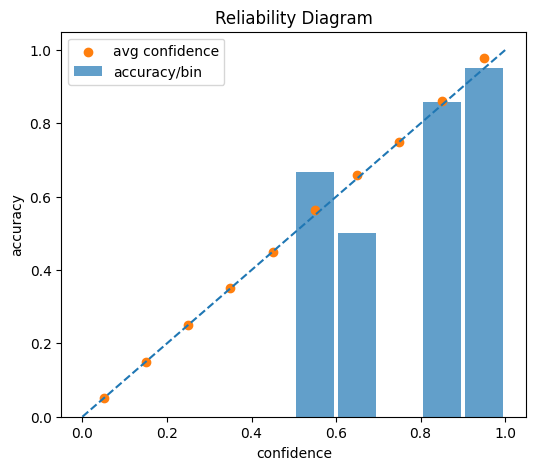

In [15]:

# 可靠度圖 + ECE
ytrue=[]; maxprob=[]; predlab=[]
for images, labels in test_ds:
    logits,_=model(images, training=False)
    la=(logits.numpy()+logit_adjustment)/best_T
    probs=tf.nn.softmax(la, axis=1).numpy()
    maxprob.extend(list(probs.max(axis=1))); predlab.extend(list(probs.argmax(axis=1))); ytrue.extend(list(labels.numpy()))
import numpy as np, matplotlib.pyplot as plt
ytrue=np.array(ytrue); maxprob=np.array(maxprob); predlab=np.array(predlab); correct=(predlab==ytrue)
bins=np.linspace(0.0,1.0,11); idx=np.digitize(maxprob, bins)-1
bin_tot=np.zeros(10); bin_cor=np.zeros(10); bin_conf=np.zeros(10)
for p,c,b in zip(maxprob, correct, idx):
    if 0<=b<10: bin_tot[b]+=1; bin_cor[b]+=1 if c else 0; bin_conf[b]+=p
bin_acc=np.zeros(10); bin_avg=np.zeros(10)
for i in range(10):
    if bin_tot[i]>0:
        bin_acc[i]=bin_cor[i]/bin_tot[i]; bin_avg[i]=bin_conf[i]/bin_tot[i]
    else:
        bin_acc[i]=0; bin_avg[i]=(i+0.5)/10.0
ece=np.sum((bin_tot/len(ytrue))*np.abs(bin_acc-bin_avg)); print('ECE:', round(float(ece),4))
plt.figure(figsize=(6,5)); plt.plot([0,1],[0,1], linestyle='--')
centers=np.linspace(0.05,0.95,10); plt.bar(centers, bin_acc, width=0.09, align='center', alpha=0.7, label='accuracy/bin')
plt.scatter(centers, bin_avg, label='avg confidence'); plt.xlabel('confidence'); plt.ylabel('accuracy'); plt.title('Reliability Diagram'); plt.legend(); plt.show()


In [16]:

# 匯出
model.save('/content/mammals_classifier.keras')
converter=tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations=[tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types=[tf.float16]
tfl=converter.convert(); open('/content/mammals_classifier.tflite','wb').write(tfl)
with open('/content/labels.txt','w') as f:
    for c in class_names: f.write(c+'\n')
with zipfile.ZipFile('/content/release_artifacts.zip','w',zipfile.ZIP_DEFLATED) as z:
    z.write('/content/mammals_classifier.keras', arcname='mammals_classifier.keras')
    z.write('/content/mammals_classifier.tflite', arcname='mammals_classifier.tflite')
    z.write('/content/labels.txt', arcname='labels.txt')
print('Exported /content/release_artifacts.zip')


Saved artifact at '/tmp/tmpu4gokasw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  List[TensorSpec(shape=(None, 9), dtype=tf.float32, name=None), TensorSpec(shape=(None, 128), dtype=tf.float32, name=None)]
Captures:
  ... (268 resource captures omitted in the published notebook)
Exported /content/release_artifacts.zip


### Demo: single-image inference

Uses Colab's file upload. The uploaded photo (an orange cat that was not in the training data) is not republished here; the printed Top-3 probabilities are kept.


In [17]:

# Demo 上傳
uploaded = colab_files.upload()
for name,data in uploaded.items():
    from PIL import Image
    import numpy as np, matplotlib.pyplot as plt, tensorflow as tf, io as _io
    img=Image.open(_io.BytesIO(data)).convert('RGB').resize((IMG_SIZE,IMG_SIZE))
    arr=(np.array(img).astype(np.float32))[None]
    logits,emb=model.predict(arr, verbose=0)
    la=(logits+logit_adjustment)/best_T
    probs=tf.nn.softmax(la, axis=1).numpy()[0]
    top3=probs.argsort()[-3:][::-1]
    print(f'\nFile: {name}'); plt.imshow(img); plt.axis('off'); plt.show()
    for i,idx in enumerate(top3):
        print(f'Top{i+1}: {class_names[idx]} — {probs[idx]*100:.2f}%')


Saving images.webp to images.webp

File: images.webp


Top1: cat — 98.90%
Top2: tiger — 0.96%
Top3: dog — 0.04%
